In [1]:
import cv2
import kornia
import matplotlib.pyplot as plt
import numpy as np
import torch
from kornia.utils import image_to_tensor, tensor_to_image
from torch import allclose

from kornia_moons.feature import *
from kornia_moons.viz import *

In [2]:
assert isinstance(to_numpy_image('../data/strahov.png'), np.ndarray)

Let's detect ORB keypoints and convert them to and from OpenCV

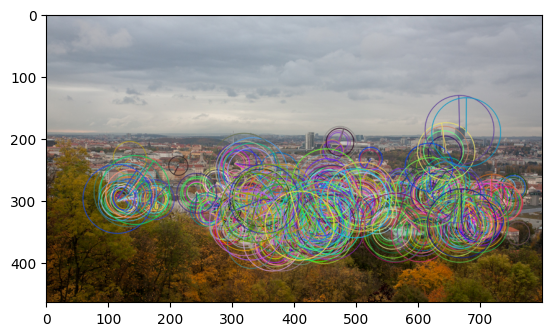

In [3]:
img = cv2.cvtColor(cv2.imread('../data/strahov.png'), cv2.COLOR_BGR2RGB)

det = cv2.ORB_create(500)
kps, descs = det.detectAndCompute(img, None)

out_img = cv2.drawKeypoints(img, kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(out_img)

In [4]:
img = cv2.cvtColor(cv2.imread('../data/strahov.png'), cv2.COLOR_BGR2RGB)

det = cv2.ORB_create(500)
kps, descs = det.detectAndCompute(img, None)
lafs, r = laf_from_opencv_kpts(kps, 1.0, with_resp=True)

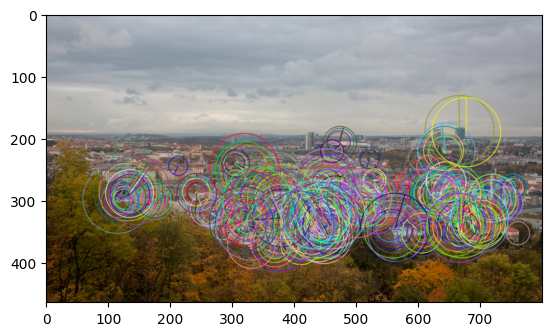

In [5]:

img = cv2.cvtColor(cv2.imread('../data/strahov.png'), cv2.COLOR_BGR2RGB)

det = cv2.ORB_create(500)
kps, descs = det.detectAndCompute(img, None)
lafs, r = laf_from_opencv_kpts(kps, 1.0, with_resp=True)
kps_back = opencv_kpts_from_laf(lafs, 1.0, r)
out_img = cv2.drawKeypoints(img, kps_back, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(out_img)

OpenCV uses different conventions for the local feature scale. 

E.g. to get equivalent kornia LAF from ORB keypoints, one should you mrSize = 0.5, 
while for SIFT -- 6.0. The orientation convention is also different for kornia and OpenCV.

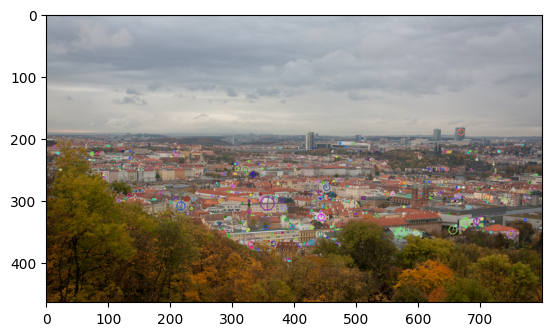

In [6]:

img = cv2.cvtColor(cv2.imread('../data/strahov.png'), cv2.COLOR_BGR2RGB)

det = cv2.SIFT_create(500)
kps, descs = det.detectAndCompute(img, None)

out_img = cv2.drawKeypoints(img, kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(out_img)

The keypoints are small, because, unlike for ORB, for SIFT OpenCV draws not real regions to be described, but the radius of the blobs, which are detected. Kornia and kornia_moons, inlike OpenCV, shows the real description region.

/var/folders/j9/y_61c9h10xz3d5g4d1rrny5c0000gn/T/ipykernel_10871/3945051170.py:2: DeprecationWarning: Since kornia 0.8.3 the `image_to_tensor` is deprecated in favor of `kornia.image.image_to_tensor`.  The `kornia.utils` module has been removed. Import from `kornia.image` instead.
  visualize_LAF(image_to_tensor(img, False), lafs, 0, 'y', figsize=(8,6))
/Users/oldufo/dev/kornia_moons/kornia_moons/feature.py:27: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is deprecated in favor of `kornia.image.tensor_to_image`.  The `kornia.utils` module has been removed. Import from `kornia.image` instead.
  img_out = tensor_to_image(img)


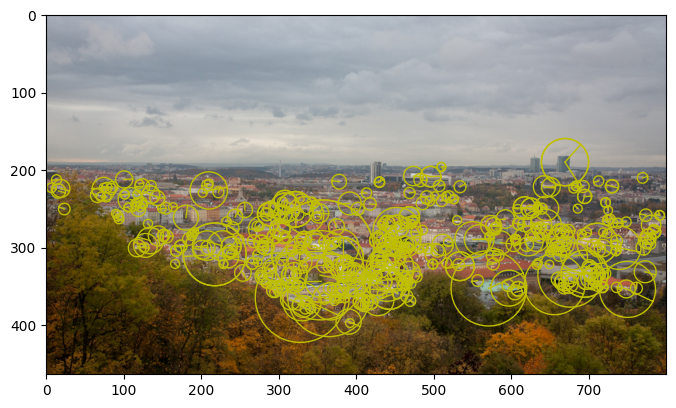

In [7]:
lafs, r = laf_from_opencv_SIFT_kpts(kps, with_resp=True)
visualize_LAF(image_to_tensor(img, False), lafs, 0, 'y', figsize=(8,6))

If you want to see the image, similar to OpenCV one, you can scale LAFs by factor 1/12.

/var/folders/j9/y_61c9h10xz3d5g4d1rrny5c0000gn/T/ipykernel_10871/854370138.py:1: DeprecationWarning: Since kornia 0.8.3 the `image_to_tensor` is deprecated in favor of `kornia.image.image_to_tensor`.  The `kornia.utils` module has been removed. Import from `kornia.image` instead.
  visualize_LAF(image_to_tensor(img, False),
/Users/oldufo/dev/kornia_moons/kornia_moons/feature.py:27: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is deprecated in favor of `kornia.image.tensor_to_image`.  The `kornia.utils` module has been removed. Import from `kornia.image` instead.
  img_out = tensor_to_image(img)


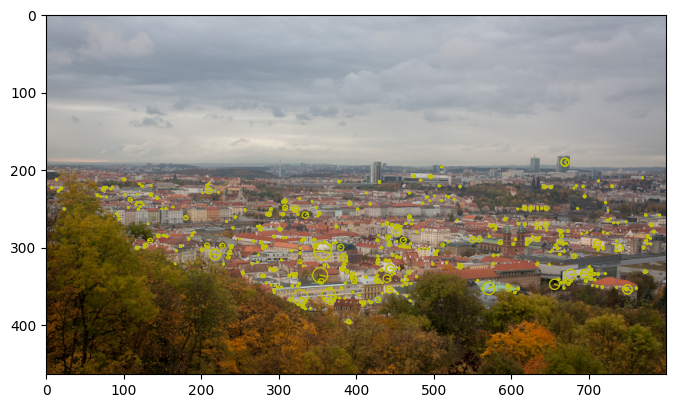

In [8]:
visualize_LAF(image_to_tensor(img, False),
              kornia.feature.laf.scale_laf(lafs, 1./6.0), 0, 'y', figsize=(8,6))

Now let's do the same for matches format

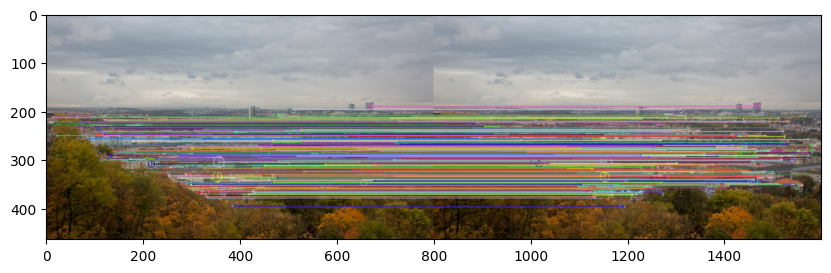

In [9]:
img = cv2.cvtColor(cv2.imread('../data/strahov.png'), cv2.COLOR_BGR2RGB)

det = cv2.SIFT_create(500)
kps, descs = det.detectAndCompute(img, None)
                                  
match_dists, match_idxs = kornia.feature.match_nn(torch.from_numpy(descs).float(),
                                             torch.from_numpy(descs).float())

cv2_matches = cv2_matches_from_kornia(match_dists, match_idxs)
out_img = cv2.drawMatches(img, kps, img, kps, cv2_matches, None,
                          flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(10,5))
plt.imshow(out_img)

match_dists_back, match_idxs_back = kornia_matches_from_cv2(cv2_matches)

assert(allclose(match_dists_back, match_dists))
assert(allclose(match_idxs_back, match_idxs))

/var/folders/j9/y_61c9h10xz3d5g4d1rrny5c0000gn/T/ipykernel_10871/4133761453.py:5: DeprecationWarning: Since kornia 0.8.3 the `image_to_tensor` is deprecated in favor of `kornia.image.image_to_tensor`.  The `kornia.utils` module has been removed. Import from `kornia.image` instead.
  timg = image_to_tensor(cv2.cvtColor(cv2.imread('../data/strahov.png'), cv2.COLOR_BGR2RGB), False).float()/255.
/Users/oldufo/dev/kornia_moons/kornia_moons/feature.py:134: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is deprecated in favor of `kornia.image.tensor_to_image`.
  img_np = (255 * kornia.tensor_to_image(x)).astype(np.uint8)
/Users/oldufo/dev/kornia_moons/kornia_moons/feature.py:157: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is deprecated in favor of `kornia.image.tensor_to_image`.
  img_np = (255 * kornia.tensor_to_image(x)).astype(np.uint8)
/Users/oldufo/dev/kornia_moons/kornia_moons/feature.py:27: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is 

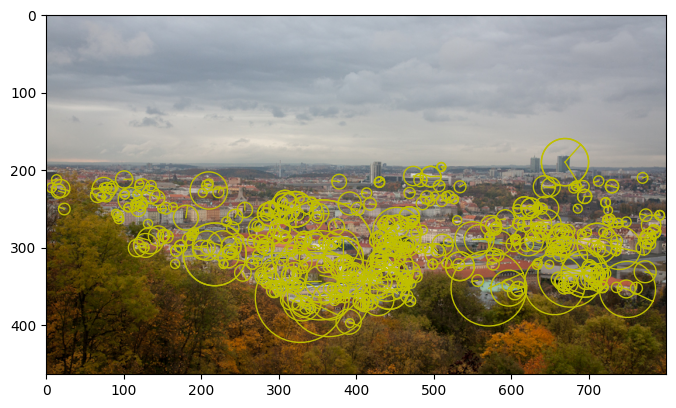

In [10]:
kornia_cv2dog = OpenCVDetectorKornia(cv2.SIFT_create(500))
kornia_cv2sift = OpenCVFeatureKornia(cv2.SIFT_create(500))


timg = image_to_tensor(cv2.cvtColor(cv2.imread('../data/strahov.png'), cv2.COLOR_BGR2RGB), False).float()/255.


lafs, r = kornia_cv2dog(timg)
lafs2, r2, descs2 = kornia_cv2sift(timg)


visualize_LAF(timg, lafs, 0, 'y', figsize=(8,6))

/var/folders/j9/y_61c9h10xz3d5g4d1rrny5c0000gn/T/ipykernel_10871/621373849.py:4: DeprecationWarning: Since kornia 0.8.3 the `image_to_tensor` is deprecated in favor of `kornia.image.image_to_tensor`.  The `kornia.utils` module has been removed. Import from `kornia.image` instead.
  timg = image_to_tensor(cv2.cvtColor(cv2.imread('../data/strahov.png'), cv2.COLOR_BGR2RGB), False).float()/255.
/Users/oldufo/dev/kornia_moons/kornia_moons/feature.py:180: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is deprecated in favor of `kornia.image.tensor_to_image`.
  img_np = (255 * kornia.tensor_to_image(x)).astype(np.uint8)


/Users/oldufo/dev/kornia_moons/kornia_moons/feature.py:27: DeprecationWarning: Since kornia 0.8.3 the `tensor_to_image` is deprecated in favor of `kornia.image.tensor_to_image`.  The `kornia.utils` module has been removed. Import from `kornia.image` instead.
  img_out = tensor_to_image(img)


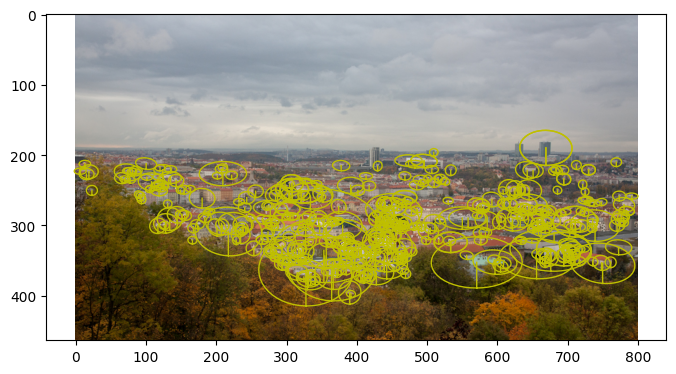

In [11]:

kornia_cv2dogaffnet = OpenCVDetectorWithAffNetKornia(cv2.SIFT_create(500), make_upright=True)


timg = image_to_tensor(cv2.cvtColor(cv2.imread('../data/strahov.png'), cv2.COLOR_BGR2RGB), False).float()/255.


lafs, r = kornia_cv2dogaffnet(timg)


visualize_LAF(timg, lafs, 0, 'y', figsize=(8,6))